<a href="https://colab.research.google.com/github/adrianamimo/dark-matter-ngc3198-simulation/blob/main/comparison_error_rotation_curve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

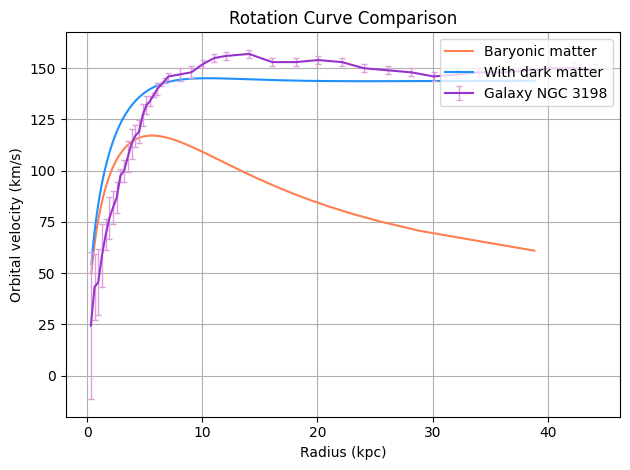

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000
G = 6.67e-11
M = 6.6821e40
r_min = 9.8742e18
r_max = 1.36017e21
M_dark = 3.04479e41
a = 9.7384e20
p_0 = 1.049e-22
h_R = 9.689e19

np.random.seed(60)

radius = np.random.gamma(shape=2, scale=h_R, size=n)

while True:
  incorrect = radius < r_min
  incorrect2 = radius > r_max
  if not np.any(incorrect) and not np.any(incorrect2):
    break
  radius[incorrect] = np.random.gamma(shape=2, scale=h_R, size=np.sum(incorrect))
  radius[incorrect2] = np.random.gamma(shape=2, scale=h_R, size=np.sum(incorrect2))

radius = np.clip(radius, r_min, r_max)

M_visible_enclosed = M * (1 - np.exp(-radius / h_R) * (1 + radius / h_R))
v = np.sqrt((G * M_visible_enclosed)/ radius)

M_dark_enclosed = 4 * np.pi * p_0 * (a**3) * (np.log(1 + radius / a) - radius / (a + radius))
M_enclosed = M_visible_enclosed + M_dark_enclosed
v_dark = np.sqrt((G * M_dark_enclosed)/ radius)
v_total = np.sqrt(v**2 + v_dark**2)

radius_kpc = radius / 3.086e19
v_kms = v / 1000
v_dark_kms = v_dark / 1000
v_total_kms = v_total / 1000

r_observable_kpc = np.array([0.32, 0.64, 0.96, 1.28, 1.61, 1.93, 2.24, 2.57, 2.89, 3.21,
                      3.54, 3.85, 4.17, 4.50, 4.82, 5.15, 5.46, 5.78, 6.10, 6.43,
                      6.74, 7.06, 8.04, 9.04, 10.04, 11.04, 12.05, 14.05, 16.07, 18.13,
                      20.05, 22.12, 24.03, 26.10, 28.16, 30.08, 32.14, 34.06, 36.12, 38.19, 40.10, 42.17, 44.08])

v_observable_kms = np.array([24.40, 43.30, 45.50, 58.50, 68.80, 76.90, 82.00, 86.90, 97.60, 100.00,
                      107.00, 113.00, 117.00, 119.00, 127.00, 132.00, 134.00, 137.00, 140.00, 142.00,
                      144.00, 146.00, 147.00, 148.00, 152.00, 155.00, 156.00, 157.00, 153.00, 153.00,
                      154.00, 153.00, 150.00, 149.00, 148.00, 146.00, 147.00, 148.00, 148.00, 149.00, 150.00, 150.00, 149.00])

e_vobs = np.array([35.90, 16.30, 16.10, 15.40, 7.61, 10.30, 8.09, 7.60, 3.03, 5.31, 7.51,
    7.32, 5.21, 5.67, 5.39, 4.34, 2.36, 0.89, 2.84, 0.88, 1.23, 1.57, 3.00,
    3.00, 2.00, 2.00, 2.00, 2.00, 2.00, 2.00, 2.00, 2.00, 2.00, 2.00, 2.00,
    2.00, 2.00, 2.00, 2.00, 2.00, 2.00, 3.00, 3.00])

order = np.argsort(radius_kpc)
r_ordered = radius_kpc[order]
v_visible_ordered = v_kms[order]
v_total_ordered = v_total_kms[order]

plt.figure()
plt.plot(r_ordered, v_visible_ordered, linestyle="-", c="coral", label="Baryonic matter")
plt.plot(r_ordered, v_total_ordered, linestyle="-", c="dodgerblue", label="With dark matter")
plt.errorbar(r_observable_kpc, v_observable_kms, yerr=e_vobs, fmt="-", color="darkorchid", ecolor="plum", elinewidth=1, capsize=2, label="Galaxy NGC 3198")
plt.legend(loc="upper right")
plt.title("Rotation Curve Comparison")
plt.xlabel("Radius (kpc)")
plt.ylabel("Orbital velocity (km/s)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [2]:
import numpy as np
import matplotlib.pyplot as plt

G = 6.67e-11
M = 6.6821e40
M_dark = 3.04479e41
a = 9.7384e20
p_0 = 1.049e-22
h_R = 9.689e19


r_observable_kpc = np.array([0.32, 0.64, 0.96, 1.28, 1.61, 1.93, 2.24, 2.57, 2.89, 3.21,
                      3.54, 3.85, 4.17, 4.50, 4.82, 5.15, 5.46, 5.78, 6.10, 6.43,
                      6.74, 7.06, 8.04, 9.04, 10.04, 11.04, 12.05, 14.05, 16.07, 18.13,
                      20.05, 22.12, 24.03, 26.10, 28.16, 30.08, 32.14, 34.06, 36.12, 38.19, 40.10, 42.17, 44.08])

v_observable_kms = np.array([24.40, 43.30, 45.50, 58.50, 68.80, 76.90, 82.00, 86.90, 97.60, 100.00,
                      107.00, 113.00, 117.00, 119.00, 127.00, 132.00, 134.00, 137.00, 140.00, 142.00,
                      144.00, 146.00, 147.00, 148.00, 152.00, 155.00, 156.00, 157.00, 153.00, 153.00,
                      154.00, 153.00, 150.00, 149.00, 148.00, 146.00, 147.00, 148.00, 148.00, 149.00, 150.00, 150.00, 149.00])

radius = r_observable_kpc * 3.086e19

M_visible_enclosed = M * (1 - np.exp(-radius / h_R) * (1 + radius / h_R))
v = np.sqrt((G * M_visible_enclosed)/ radius)

M_dark_enclosed = 4 * np.pi * p_0 * (a**3) * (np.log(1 + radius / a) - radius / (a + radius))
M_enclosed = M_visible_enclosed + M_dark_enclosed
v_dark = np.sqrt((G * M_dark_enclosed)/ radius)

v_total = np.sqrt(v**2 + v_dark**2)

radius_kpc = radius / 3.086e19
v_kms = v / 1000
v_dark_kms = v_dark / 1000
v_total_kms = v_total / 1000

difference = v_observable_kms - v_total_kms
rmse = np.sqrt(np.mean(difference**2))
mae = np.mean(np.abs(difference))

difference2 = v_observable_kms - v_kms
rmse2 = np.sqrt(np.mean(difference2**2))
mae2 = np.mean(np.abs(difference2))

print("Errors for the galazy with dark matter (blue line):")
print(f"Root Mean Square Error (RMSE): {rmse:.3f}")
print(f"Mean absolute error (MAE): {mae:.3f}")
print("\n")
print("Errors for the galaxy without dark matter (orange line)")
print(f"Root Mean Square Error (RMSE): {rmse2:.3f}")
print(f"Mean absolute error (MAE): {mae2:.3f}")

Errors for the galazy with dark matter (blue line):
Root Mean Square Error (RMSE): 16.947
Mean absolute error (MAE): 12.812


Errors for the galaxy without dark matter (orange line)
Root Mean Square Error (RMSE): 51.625
Mean absolute error (MAE): 42.555
